In [1]:
import xgboost as xgb
print(xgb.__version__)

3.3.0


In [2]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
import matplotlib.pyplot as plt

In [3]:
train = pd.read_csv("train.csv")
val   = pd.read_csv("validation.csv")
test  = pd.read_csv("test.csv")

In [5]:
TARGET = "LST"

X_train = train.drop(columns=TARGET)
y_train = train[TARGET]

X_val = val.drop(columns=TARGET)
y_val = val[TARGET]

X_test = test.drop(columns=TARGET)
y_test = test[TARGET]

In [8]:
model = XGBRegressor(

    # Trees
    n_estimators=1000,
    max_depth=10,

    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    min_child_weight=3,

    reg_alpha=0.2,
    reg_lambda=2,

    objective="reg:squarederror",

    tree_method="hist",
    device="cuda",

    random_state=42
)

In [9]:
model.fit(

    X_train,
    y_train,

    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],

    verbose=50
)

[0]	validation_0-rmse:9.06747	validation_1-rmse:10.46635
[50]	validation_0-rmse:1.42988	validation_1-rmse:4.73914
[100]	validation_0-rmse:1.11621	validation_1-rmse:4.37985
[150]	validation_0-rmse:1.04035	validation_1-rmse:4.35180
[200]	validation_0-rmse:0.98165	validation_1-rmse:4.34938
[250]	validation_0-rmse:0.93955	validation_1-rmse:4.35261
[300]	validation_0-rmse:0.90726	validation_1-rmse:4.36319
[350]	validation_0-rmse:0.87708	validation_1-rmse:4.37002
[400]	validation_0-rmse:0.84955	validation_1-rmse:4.36950
[450]	validation_0-rmse:0.82757	validation_1-rmse:4.36340
[500]	validation_0-rmse:0.80307	validation_1-rmse:4.37593
[550]	validation_0-rmse:0.78142	validation_1-rmse:4.36901
[600]	validation_0-rmse:0.76256	validation_1-rmse:4.36750
[650]	validation_0-rmse:0.74410	validation_1-rmse:4.36603
[700]	validation_0-rmse:0.72704	validation_1-rmse:4.36068
[750]	validation_0-rmse:0.70954	validation_1-rmse:4.36123
[800]	validation_0-rmse:0.69317	validation_1-rmse:4.35994
[850]	validation

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [10]:
pred = model.predict(X_test)

/home/vansh/ML/lib/python3.12/site-packages/xgboost/core.py:553: UserWarning: [06:18:12] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [11]:
mae = mean_absolute_error(y_test, pred)

rmse = np.sqrt(mean_squared_error(y_test, pred))

r2 = r2_score(y_test, pred)

print(f"MAE : {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²  : {r2:.4f}")

MAE : 2.101
RMSE: 2.571
R²  : 0.8995


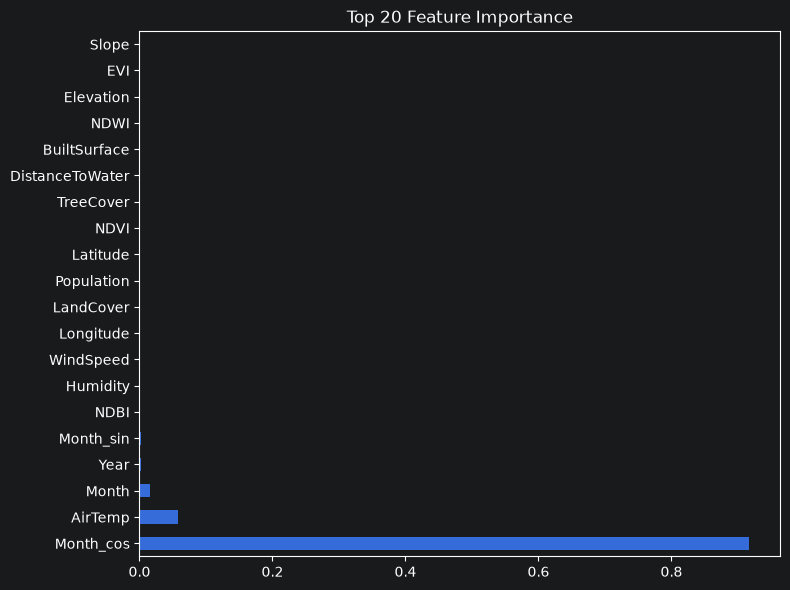

In [15]:
DROP_COLUMNS = [
    "LST",
    "system:index",
    ".geo"
]
FEATURES = [c for c in train.columns if c not in DROP_COLUMNS]

importance = pd.Series(
    model.feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

plt.figure(figsize=(8,6))
importance.head(20).plot(kind="barh")
plt.title("Top 20 Feature Importance")
plt.tight_layout()
plt.show()

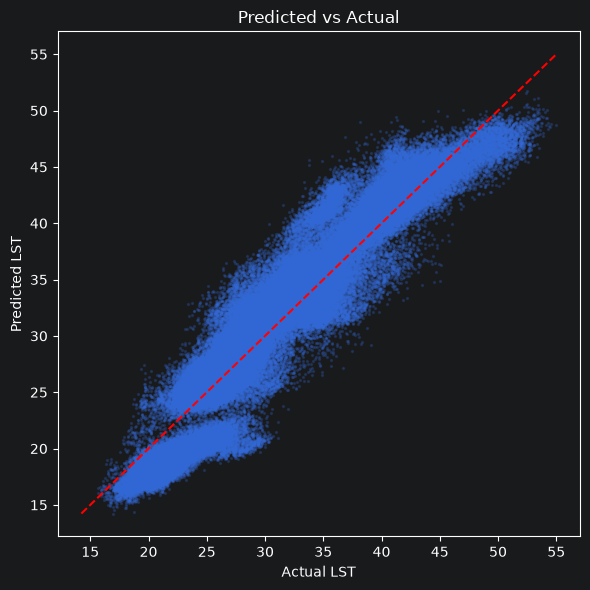

In [16]:
plt.figure(figsize=(6,6))

plt.scatter(
    y_test,
    pred,
    s=2,
    alpha=0.2
)

lims = [
    min(y_test.min(), pred.min()),
    max(y_test.max(), pred.max())
]

plt.plot(lims, lims, 'r--')

plt.xlabel("Actual LST")
plt.ylabel("Predicted LST")
plt.title("Predicted vs Actual")
plt.tight_layout()
plt.show()

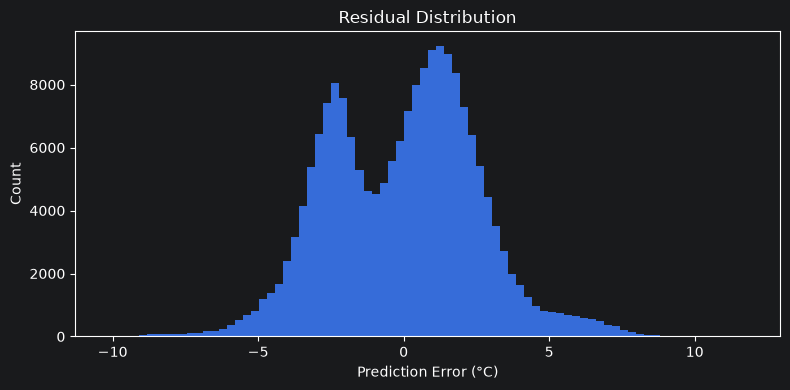

In [17]:
residuals = pred - y_test

plt.figure(figsize=(8,4))
plt.hist(residuals, bins=80)

plt.xlabel("Prediction Error (°C)")
plt.ylabel("Count")

plt.title("Residual Distribution")

plt.tight_layout()
plt.show()